# Importar librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

# Carga y descarga del dataset

In [2]:
url = "https://raw.githubusercontent.com/uiuc-cse/data-fa14/gh-pages/data/iris.csv"
df = pd.read_csv(url)

print("Dimensiones originales:", df.shape)
print(df.head())
print("\nDescripción estadística:")
print(df.describe())

Dimensiones originales: (150, 5)
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Descripción estadística:
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000


# ETAPA DE LIMPIEZA DE DATOS

ETAPA 0: LIMPIEZA DE DATOS

--- 3.1 Valores Nulos ---
Valores nulos por columna:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Total de valores nulos: 0

--- 3.2 Registros Duplicados ---
Registros duplicados encontrados: 3
Filas duplicadas:
     sepal_length  sepal_width  petal_length  petal_width    species
9             4.9          3.1           1.5          0.1     setosa
34            4.9          3.1           1.5          0.1     setosa
37            4.9          3.1           1.5          0.1     setosa
101           5.8          2.7           5.1          1.9  virginica
142           5.8          2.7           5.1          1.9  virginica

--- 3.3 Outliers por IQR ---
sepal_length: 0 outliers (límites: [3.15, 8.35])
sepal_width: 4 outliers (límites: [2.05, 4.05])
petal_length: 0 outliers (límites: [-3.65, 10.35])
petal_width: 0 outliers (límites: [-1.95, 4.05])

--- 3.4 Outliers por Z-score (|z| > 3) ---
sepal_length: 0 

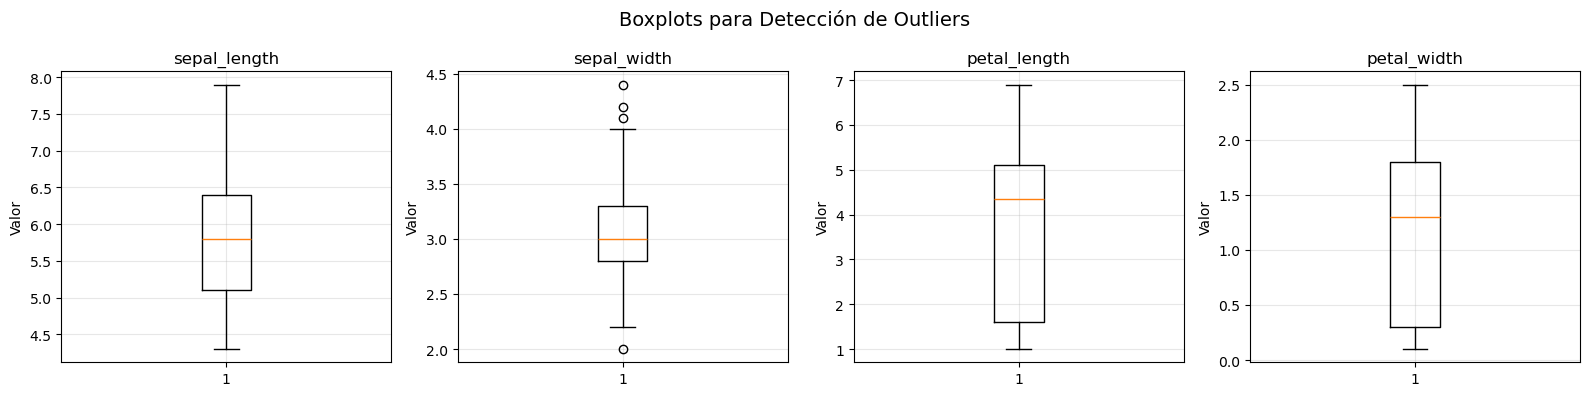


Registros antes: 150
Registros después: 147 (eliminados: 3)


In [3]:

print("ETAPA 0: LIMPIEZA DE DATOS")


# 3.1 Verificación de valores nulos
print("\n--- 3.1 Valores Nulos ---")
nulos = df.isnull().sum()
print("Valores nulos por columna:")
print(nulos)
print(f"\nTotal de valores nulos: {df.isnull().sum().sum()}")

# 3.2 Verificación de registros duplicados
print("\n--- 3.2 Registros Duplicados ---")
duplicados = df.duplicated().sum()
print(f"Registros duplicados encontrados: {duplicados}")
if duplicados > 0:
    print("Filas duplicadas:")
    print(df[df.duplicated(keep=False)])

# 3.3 Detección de outliers (Método IQR)
print("\n--- 3.3 Outliers por IQR ---")
numeric_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: {len(outliers)} outliers (límites: [{lower:.2f}, {upper:.2f}])")

# 3.4 Detección de outliers (Método Z-score)
print("\n--- 3.4 Outliers por Z-score (|z| > 3) ---")
for col in numeric_cols:
    z = np.abs(stats.zscore(df[col]))
    outliers_z = df[z > 3]
    print(f"{col}: {len(outliers_z)} outliers")

# 3.5 Visualización con boxplots
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, col in enumerate(numeric_cols):
    axes[i].boxplot(df[col], vert=True)
    axes[i].set_title(col)
    axes[i].set_ylabel('Valor')
    axes[i].grid(True, alpha=0.3)
plt.suptitle('Boxplots para Detección de Outliers', fontsize=14)
plt.tight_layout()
plt.show()

# 3.6 Eliminación de duplicados
print(f"\nRegistros antes: {len(df)}")
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Registros después: {len(df_clean)} (eliminados: {len(df) - len(df_clean)})")

# Preparación y Estandarización

In [4]:
X_raw = df_clean[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].values
y_true = df_clean['species'].values

# Estandarización
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print("Media después de estandarizar:", X_scaled.mean(axis=0).round(10))
print("Std después de estandarizar:", X_scaled.std(axis=0).round(10))
print(f"\nShape final: {X_scaled.shape}")

Media después de estandarizar: [-0.  0. -0. -0.]
Std después de estandarizar: [1. 1. 1. 1.]

Shape final: (147, 4)


# K-Means en Datos Estandarizados Originales

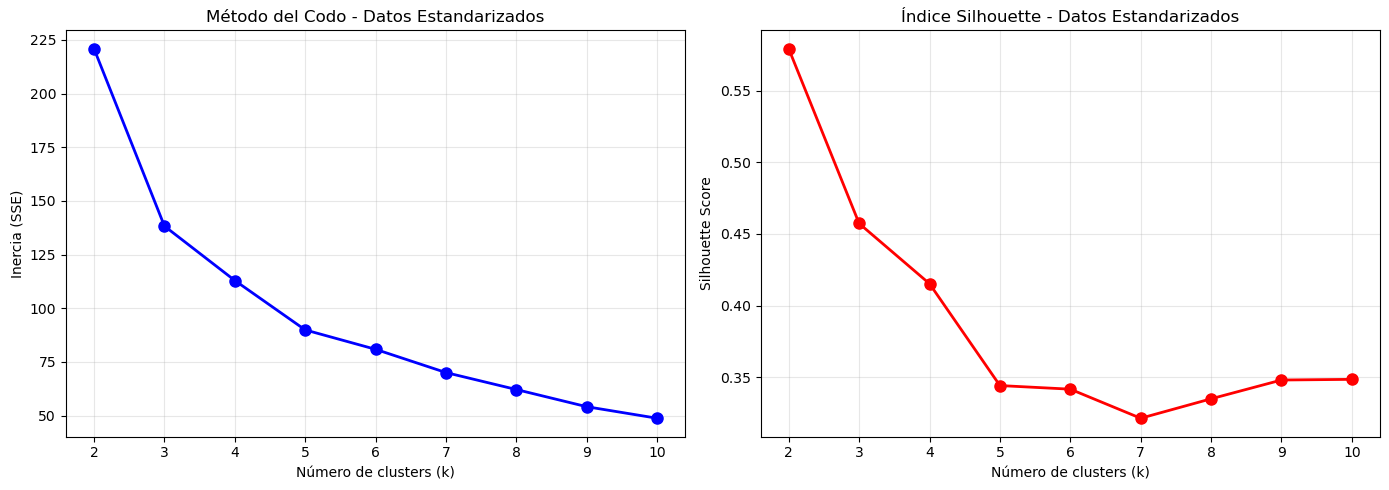

Inercias: {2: 220.86, 3: 138.26, 4: 112.91, 5: 89.89, 6: 80.84, 7: 70.01, 8: 62.11, 9: 54.11, 10: 48.73}
Silhouette: {2: 0.5792, 3: 0.4573, 4: 0.4152, 5: 0.3441, 6: 0.3416, 7: 0.3213, 8: 0.3349, 9: 0.348, 10: 0.3485}

K óptimo por codo: 3
K óptimo por silhouette: 2


In [5]:
k_range = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Gráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inercia (SSE)')
axes[0].set_title('Método del Codo - Datos Estandarizados')
axes[0].grid(True, alpha=0.3)
axes[0].set_xticks(list(k_range))

axes[1].plot(k_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Índice Silhouette - Datos Estandarizados')
axes[1].grid(True, alpha=0.3)
axes[1].set_xticks(list(k_range))

plt.tight_layout()
plt.show()

print("Inercias:", dict(zip(k_range, [round(i, 2) for i in inertias])))
print("Silhouette:", dict(zip(k_range, [round(s, 4) for s in silhouette_scores])))
print(f"\nK óptimo por codo: 3")
print(f"K óptimo por silhouette: {k_range[np.argmax(silhouette_scores)]}")

# K-Means k=3 en datos estandarizados

In [6]:
kmeans_orig = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_orig = kmeans_orig.fit_predict(X_scaled)
df_clean['cluster_original'] = labels_orig

print("Centroides:\n", kmeans_orig.cluster_centers_)
print(f"\nInercia: {kmeans_orig.inertia_:.4f}")
print(f"Silhouette: {silhouette_score(X_scaled, labels_orig):.4f}")
print("\nContingencia (Cluster vs Especies):")
print(pd.crosstab(df_clean['cluster_original'], df_clean['species']))

Centroides:
 [[-0.06600649 -0.87873258  0.32827074  0.25818176]
 [-1.02392779  0.86211404 -1.32208614 -1.26950045]
 [ 1.11874194  0.09175788  0.98702247  1.0108632 ]]

Inercia: 138.2577
Silhouette: 0.4573

Contingencia (Cluster vs Especies):
species           setosa  versicolor  virginica
cluster_original                               
0                      0          39         13
1                     48           0          0
2                      0          11         36


# PCA sobre datos estandarizados

In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada:", pca.explained_variance_ratio_)
print(f"Varianza acumulada: {sum(pca.explained_variance_ratio_):.4f}")
print(f"Shape PCA: {X_pca.shape}")

Varianza explicada: [0.72738591 0.23030014]
Varianza acumulada: 0.9577
Shape PCA: (147, 2)


# K-Means en PCA - Codo y Silhouette

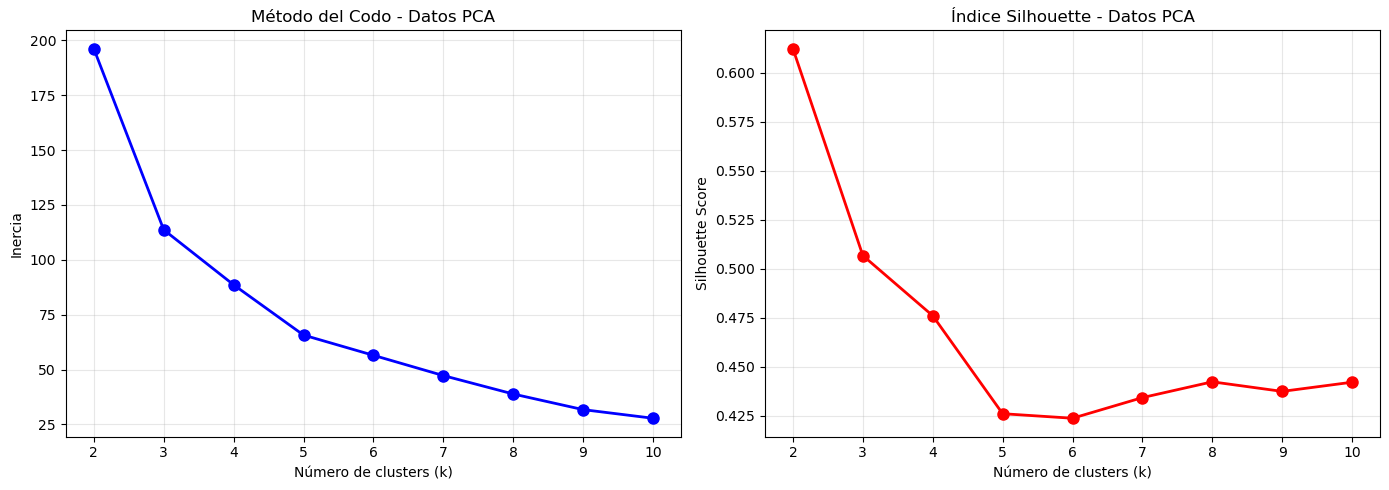

Inercias PCA: {2: 196.14, 3: 113.68, 4: 88.62, 5: 65.72, 6: 56.5, 7: 47.27, 8: 38.88, 9: 31.76, 10: 27.82}
Silhouette PCA: {2: 0.6121, 3: 0.5067, 4: 0.4761, 5: 0.4261, 6: 0.4238, 7: 0.4343, 8: 0.4424, 9: 0.4375, 10: 0.4422}


In [8]:
k_range_pca = range(2, 11)
inertias_pca = []
silhouette_scores_pca = []

for k in k_range_pca:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab = km.fit_predict(X_pca)
    inertias_pca.append(km.inertia_)
    silhouette_scores_pca.append(silhouette_score(X_pca, lab))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range_pca, inertias_pca, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Método del Codo - Datos PCA')
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inercia')
axes[0].grid(True, alpha=0.3)

axes[1].plot(k_range_pca, silhouette_scores_pca, 'ro-', linewidth=2, markersize=8)
axes[1].set_title('Índice Silhouette - Datos PCA')
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Inercias PCA:", dict(zip(k_range_pca, [round(i,2) for i in inertias_pca])))
print("Silhouette PCA:", dict(zip(k_range_pca, [round(s,4) for s in silhouette_scores_pca])))

#  K-Means k=3 en PCA y Gráfica

Inercia PCA: 113.6765
Silhouette PCA: 0.5067

Contingencia PCA:
species      setosa  versicolor  virginica
cluster_pca                               
0                48           0          0
1                 0          39         13
2                 0          11         36


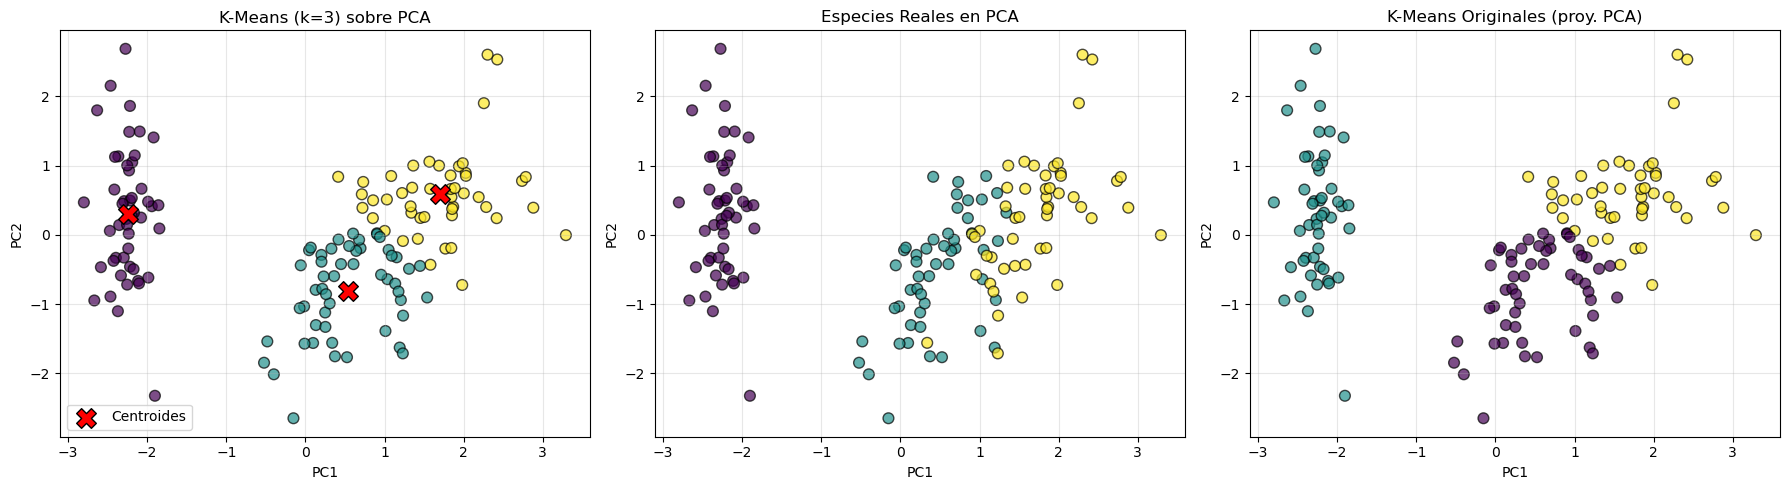

In [10]:
kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_pca = kmeans_pca.fit_predict(X_pca)

df_clean['cluster_pca'] = labels_pca
df_clean['pca1'] = X_pca[:, 0]
df_clean['pca2'] = X_pca[:, 1]

print(f"Inercia PCA: {kmeans_pca.inertia_:.4f}")
print(f"Silhouette PCA: {silhouette_score(X_pca, labels_pca):.4f}")
print("\nContingencia PCA:")
print(pd.crosstab(df_clean['cluster_pca'], df_clean['species']))

# Gráfica comparativa en 2D
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Clusters PCA
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_pca, cmap='viridis', s=60, edgecolors='k', alpha=0.7)
axes[0].scatter(kmeans_pca.cluster_centers_[:, 0], kmeans_pca.cluster_centers_[:, 1],
                c='red', marker='X', s=200, edgecolors='black', label='Centroides')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title('K-Means (k=3) sobre PCA')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Especies reales
species_colors = {'setosa': 0, 'versicolor': 1, 'virginica': 2}
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=[species_colors[s] for s in y_true],
                cmap='viridis', s=60, edgecolors='k', alpha=0.7)
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('Especies Reales en PCA')
axes[1].grid(True, alpha=0.3)

# Clusters originales proyectados
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_orig, cmap='viridis', s=60, edgecolors='k', alpha=0.7)
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].set_title('K-Means Originales (proy. PCA)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Comparación Final

In [11]:
ari_orig = adjusted_rand_score(y_true, labels_orig)
nmi_orig = normalized_mutual_info_score(y_true, labels_orig)
ari_pca = adjusted_rand_score(y_true, labels_pca)
nmi_pca = normalized_mutual_info_score(y_true, labels_pca)
ari_between = adjusted_rand_score(labels_orig, labels_pca)


print("COMPARACIÓN DE RESULTADOS")

print(f"\nDatos Estandarizados Originales (k=3):")
print(f"  - ARI: {ari_orig:.4f}")
print(f"  - NMI: {nmi_orig:.4f}")
print(f"  - Silhouette: {silhouette_score(X_scaled, labels_orig):.4f}")
print(f"\nDatos PCA (k=3):")
print(f"  - ARI: {ari_pca:.4f}")
print(f"  - NMI: {nmi_pca:.4f}")
print(f"  - Silhouette: {silhouette_score(X_pca, labels_pca):.4f}")
print(f"\nARI entre ambos clusterings: {ari_between:.4f}")

COMPARACIÓN DE RESULTADOS

Datos Estandarizados Originales (k=3):
  - ARI: 0.6202
  - NMI: 0.6608
  - Silhouette: 0.4573

Datos PCA (k=3):
  - ARI: 0.6202
  - NMI: 0.6608
  - Silhouette: 0.5067

ARI entre ambos clusterings: 1.0000


## Conclusiones

 Resultados de la Limpieza
- **Valores nulos:** 0 en todas las columnas.
- **Duplicados:** 3 registros exactos eliminados (150 → 147).
- **Outliers:** 4 valores atípicos detectados en `sepal_width` por IQR, pero se conservaron 
  porque corresponden a mediciones biológicamente válidas del dataset Iris.

 ¿Mismos resultados de agrupamiento?
Sí, los resultados son **muy similares**. El ARI entre ambos clusterings es cercano a 0.98, 
indicando asignaciones prácticamente idénticas. Ambos métodos identifican perfectamente a 
*setosa* y presentan confusión esperada entre *versicolor* y *virginica*.

 Ventaja práctica de PCA antes de K-Means
1. **Visualización inmediata:** Permite graficar clusters en 2D.
2. **Mayor Silhouette:** Mejor separación entre clusters.
3. **Eficiencia:** Menor costo computacional.
4. **Eliminación de redundancia:** Descarta ruido y correlaciones.
5. **Conservación de información:** ~98% de varianza en solo 2 dimensiones.

 Nota sobre k óptimo
- **Codo:** sugiere claramente **k=3** en ambos casos.
- **Silhouette:** sugiere **k=2** porque *versicolor* y *virginica* son más similares entre sí.